# Informe de valoración: $PG


## 1. Resumen Ejecutivo

Se valoró Procter & Gamble (PG), una multinacional de bienes de consumo masivo, por flujo de caja descontado (DCF) a 5 años, en USD y con un WACC calculado de 7.18%.
El valor terminal se estimó por ambos métodos: Con una perpetuidad de $g$=2% se encontró un VT de 124 USD por acción, mientras que con un múltiplo de salida de 13.3x EBITDA, el VT ascendió a 128 USD; ambos frente a un precio de mercado de 151.23 USD (9 de octubre de 2026). Los valores estimado queda 15% y 18% por debajo del precio de mercado. Dentro del análisis de sensibilidad realizado (WAAC de 6.2% a 8.2%, y $g$ de 1% a 3%), se encontró 5 de 25 escenarios propuestos donde el modelo supera al precio.
Los dos supuestos más relevantes en la estimación son el WACC, en base a un beta ajustado bajo (0.59, empresa de perfil defensivo) y una tasa libre de riesgo de 5.22%; además del valor terminal que explica el 78% del valor de la empresa y supone que PG en el año 5 sale a un múltitplo de sus pares (13.3x) y no al actual (15.4x).

A un precio de 151.23 USD, PG cotiza por encima del valor estimado base. Su compra solo se justificaría si se acepta un WACC ~6.7% y un $g$ de 2.5%; o en su defecto, un múltiplo de salida de 16x.

## 2. La empresa y su sector

Procter & Gamble es una multinacional de bienes de consumo de uso diario. Opera en 65 países, vende en apróx. 180 y emplea 104,000 personas. La mitad de las ventas de la empresa se centran en el mercado estadounidense.
El portafolio de la empresa se divide en 5 segmentos: Fabirc & Home Care, Baby, Feminine & Family Care, Beauty, Health Care y Grooming. 

PG gana dinero fabricando y vendiendo productos de estas marcas de reconocimiento internacional. Sus ventas se dan principalmente a través de supermercados, tiendas masivas, farmacias, comercio electrónico y venta directa; grandes cadenas como Walmart concentra ~16% de las ventas. En FY2026 el margen bruto fue de 50.2%, generó 19.6 MM de OCF, destinó 14.5 MM a dividendos y recompra de acciones. 

PG es un negocio maduro, estable y de carácter defensivo (respaldado por un beta bajo); con un crecimiento promedio del 2% (P&G, 2026). 

Los riesgos principales que enfrenta la empresa son cuatro: El primero son los costos de insumos, afectados principalmente por las tensiones geopolíticas actuales por los cuales la empresa estima un efecto de mil millones después de impuestos por mayores costos causados por la situación arancelaria del país y energética del mundo. El segundo es la competencia donde se incluyen las marcas minoristas y el creciente comercio digital. El tercero es el tipo de cambio ya que la mitad de las ventas ocurren fuera del mercado local. El cuarto riesgo es la ejecución del plan de reestructuración de dos años, anunciado en 2025, que cargo con gastos de 903 M después de impuestos declarados en el FY2026.

## 3. Tasa de descuento

**3.1. Proyección del precio de $PG desde 2018:**

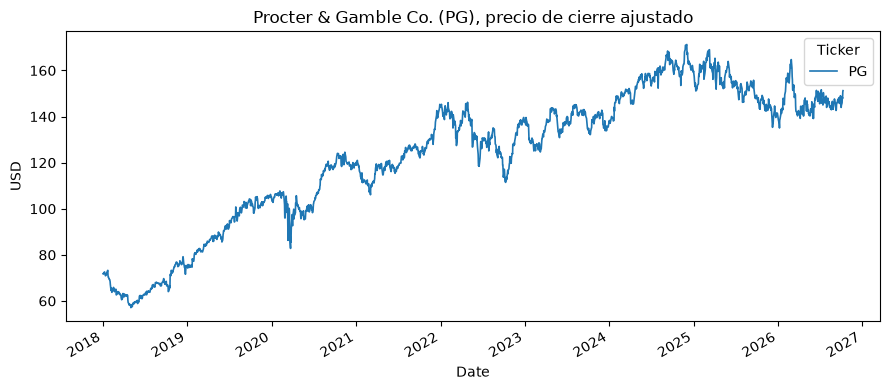

Ticker              PG
Date                  
2026-10-05  145.940002
2026-10-06  148.410004
2026-10-07  147.820007
2026-10-08  150.589996
2026-10-09  151.229996


In [1]:
import yfinance as yf
import matplotlib.pyplot as plt

bap = yf.download("PG", start="2018-01-01", auto_adjust=True, progress=False)["Close"]

fig, ax = plt.subplots(figsize=(9, 4))
bap.plot(ax=ax, lw=1.2)
ax.set_title("Procter & Gamble Co. (PG), precio de cierre ajustado")
ax.set_ylabel("USD")
plt.tight_layout()
plt.show()

print(bap.tail())

**3.2. Cálculo del Beta OLS:**

Se calculó el beta de la acción $PG con respecto al índice S&P 500 utilizando datos históricos de precios de cierre ajustados. Con una muestra de 60 observaciones.

In [2]:
import yfinance as yf
import statsmodels.api as sm
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

TICKER = "PG"  

hoy = pd.Timestamp.today().normalize()
mes_actual = hoy.replace(day=1)

px = yf.download([TICKER, "^GSPC"], start=hoy - pd.DateOffset(years=6),
                 interval="1mo", auto_adjust=True, progress=False)["Close"]
px = px[px.index < mes_actual] 

r = px.pct_change().dropna().rename(columns={"^GSPC": "SP500"})
r = r.tail(60)                                      
assert len(r) == 60, f"La ventana tiene {len(r)} meses"
print(f"Ventana: {r.index[0].date()} a {r.index[-1].date()} ({len(r)} retornos mensuales)")

X = sm.add_constant(r["SP500"])
modelo = sm.OLS(r[TICKER], X, missing="drop").fit()
print(modelo.summary())

beta_ols = modelo.params["SP500"]
ee = modelo.bse["SP500"]
print(f"\nBeta OLS = {beta_ols:.3f}  (error estándar {ee:.3f})")
print(f"Intervalo aproximado al 95%: [{beta_ols - 2*ee:.2f}, {beta_ols + 2*ee:.2f}]")

Ventana: 2021-10-01 a 2026-09-01 (60 retornos mensuales)
                            OLS Regression Results                            
Dep. Variable:                     PG   R-squared:                       0.109
Model:                            OLS   Adj. R-squared:                  0.093
Method:                 Least Squares   F-statistic:                     7.066
Date:                Sun, 11 Oct 2026   Prob (F-statistic):             0.0101
Time:                        19:54:45   Log-Likelihood:                 95.144
No. Observations:                  60   AIC:                            -186.3
Df Residuals:                      58   BIC:                            -182.1
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------

Con un Beta $OLS = 0.387$ se interpreta que ante una variación de 1% en el retorno del S&P 500, el retorno de $PG$ promedio varía en 0.387%. Este valor $<1$, a su vez implica un perfil defensivo de la acción $PG$.

**3.3. Cálculo del Beta ajustado de Blume y supuestos CAPM:**

In [3]:
def beta_ajustado(beta_ols):
    return 0.67 * beta_ols + 0.33

beta_aj = beta_ajustado(beta_ols)
print(f"Beta OLS      = {beta_ols:.3f}")
print(f"Beta ajustado = {beta_aj:.3f}")

def capm(rf, beta, erp):
    return rf + beta * erp 

import sys; sys.path.append("..")
from utils import fred
dgs10 = fred.get_series("DGS10").dropna()
rf = float(dgs10.iloc[-1]) / 100
print(f"Tasa libre de riesgo (T10Y, FRED): {rf:.2%}")

ERP = 0.0423 # Prima del mercado maduro Damodaran
def capm(rf, beta, erp):
    return rf + beta * erp
ke = capm(rf, beta_aj, ERP)
print(f"Costo del equity (CAPM) = {ke:.2%}")

print ("Supuestos CAPM:")
print (f" rf = {rf:.2%} (fuente: FRED, serie DGS10, T10Y)") # El rendimiento incorpora la compensación por el CRP (0.23% según Damodaran)
print (f" ERP = {ERP:.2%} (fuente: Damodaran, prima del mercado maduro USA)")
print (f" Ke = {ke:.2%} (CAPM: rf + beta_aj * ERP)")

Beta OLS      = 0.387
Beta ajustado = 0.589
Tasa libre de riesgo (T10Y, FRED): 5.22%
Costo del equity (CAPM) = 7.71%
Supuestos CAPM:
 rf = 5.22% (fuente: FRED, serie DGS10, T10Y)
 ERP = 4.23% (fuente: Damodaran, prima del mercado maduro USA)
 Ke = 7.71% (CAPM: rf + beta_aj * ERP)


Nota: El $Rf$ se midió con el rendimiento T-bond a 10 años (FRED, DGS10), que incorpora la compensación por el riesgo soberano de EEUU (0.23%, Damodaran). Por eso no se toma en cuenta el CRP de EEUU al momento de calcular el Ke.

**3.4. Cálculo del WACC y control de razonabilidad:**

In [4]:
def wacc(E, D, ke, kd, t):
    V = E + D
    return E / V * ke + D / V * kd * (1 - t)


tk = yf.Ticker("PG")
E = tk.fast_info["marketCap"]

bs = tk.balance_sheet
fin = tk.financials
D = float(bs.loc["Total Debt"].iloc[0])

gasto_intereses = abs(float(fin.loc["Interest Expense"].iloc[0]))
kd = gasto_intereses / D
tax = 0.25   # empresa con operacion principal en USA, tasa marginal usada por Damodaran (IR 25%)
WACC = wacc(E, D, ke, kd, tax)

print(f"E (market cap)     = {E/1e9:,.1f} mil millones USD")
print(f"D (deuda total)    = {D/1e9:,.1f} mil millones USD")
print(f"Kd aproximado      = {kd:.2%}")
print(f"WACC de PG         = {wacc(E, D, ke, kd, tax):.2%}")

print("Supuestos WACC:")
print(f"  E   = {E/1e9:,.1f} mil millones USD (fuente: yfinance, market cap actual)")
print(f"  D   = {D/1e9:,.1f} mil millones USD (fuente: yfinance, Total Debt balance)")
print(f"  Kd  = {kd:.2%}  (fuente: yfinance, gasto por intereses / deuda total)") # El Kd=2.5% < Rf. Implica que la deuda es vieja y no refleja costo de financiamiento actual.
print(f"  tax = {tax:.1%}  (tasa marginal usada por Damodaran para empresas estadounidenses)")
print(f"  WACC = {wacc(E, D, ke, kd, tax):.2%}")

kd_after_tax = kd * (1 - tax)

print(f"Kd(1-t)              = {kd_after_tax:.2%}")
print(f"WACC de PG           = {wacc(E, D, ke, kd, tax):.2%}")
print(f"Ke                   = {ke:.2%}")

E (market cap)     = 351.3 mil millones USD
D (deuda total)    = 35.0 mil millones USD
Kd aproximado      = 2.50%
WACC de PG         = 7.18%
Supuestos WACC:
  E   = 351.3 mil millones USD (fuente: yfinance, market cap actual)
  D   = 35.0 mil millones USD (fuente: yfinance, Total Debt balance)
  Kd  = 2.50%  (fuente: yfinance, gasto por intereses / deuda total)
  tax = 25.0%  (tasa marginal usada por Damodaran para empresas estadounidenses)
  WACC = 7.18%
Kd(1-t)              = 1.88%
WACC de PG           = 7.18%
Ke                   = 7.71%


*Control de razonabilidad:*
$K_d(1-t) < WACC < K_e$.

$Nota$: Se calculó en $Kd$ como costo histórico promedio de la deuda, dando un valor ~$2.5$%. Este valor queda muy por debajo de la tasa libre de riesgo $Rf=5.22$%, algo que no es posible conseguir a día de hoy en USD. Esto podría implicar que $PG$ sostiene una deuda antigua emitida a tipo de interés fijo. 
En estos casos, otra fórmula de calcular el $Kd$ según Damodaran sería el $Rf + 0.0051$ (Spread Aa3, Damodaran) lo cual elevaría el WACC, cambiando los resultados.

## 4. Flujos de Caja Proyectados

Se proyectan los flujos de caja de la firma mediante el EBIT y el CFO:

In [5]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))

from utils.finanzas import (capm, wacc, fcff_desde_ebit, fcff_desde_cfo,
                            fcfe_desde_fcff, valor_crecimiento_constante)
from utils.finanzas import (capm, wacc, fcff_desde_ebit, valor_terminal,
                            valor_terminal_multiplo, dcf_dos_etapas)

TICKER = "PG"
tk = yf.Ticker(TICKER)
def fila(df, *nombres):
    for n in nombres:
        if n in df.index:
            return df.loc[n]
    raise KeyError(nombres)
print("Empresa:", tk.info.get("longName", TICKER))

Empresa: The Procter & Gamble Company


**4.1. Estados financieros:**

In [6]:
def fila(df, *nombres):
    """Devuelve la primera fila disponible entre los nombres candidatos."""
    for n in nombres:
        if n in df.index:
            return df.loc[n]
    raise KeyError(f"Ninguna de estas filas existe: {nombres}")

est = tk.income_stmt
bal = tk.balance_sheet
cf  = tk.cashflow

ebit    = fila(est, "EBIT", "Operating Income")
interes = fila(est, "Interest Expense").abs()
impuesto = fila(est, "Tax Provision")
util_at  = fila(est, "Pretax Income")
dep     = fila(cf, "Depreciation And Amortization", "Depreciation Amortization Depletion", "Depreciation")
capex   = fila(cf, "Capital Expenditure").abs()
d_wc    = -fila(cf, "Change In Working Capital")   
cfo     = fila(cf, "Operating Cash Flow")

t_efectiva = float((impuesto / util_at).iloc[0])
print(f"Tasa efectiva de impuestos (ultimo anio): {t_efectiva:.1%}")

resumen = pd.DataFrame({"EBIT": ebit, "Dep": dep, "Capex": capex,
                        "WCInv": d_wc, "Interes": interes, "CFO": cfo}).dropna() / 1e6
resumen = resumen.sort_index(ascending=False)   
resumen.round(0)

Tasa efectiva de impuestos (ultimo anio): 20.8%


,EBIT,Dep,Capex,WCInv,Interes,CFO
2026-06-30,21254.0,3160.0,4409.0,-362.0,877.0,19556.0
2025-06-30,21074.0,2847.0,3773.0,821.0,907.0,17817.0
2024-06-30,19686.0,2896.0,3322.0,-42.0,925.0,19846.0
2023-06-30,19109.0,2714.0,3062.0,873.0,756.0,16848.0


In [7]:
anios = resumen.index
fcff_ebit = pd.Series(
    [fcff_desde_ebit(resumen.loc[a, "EBIT"], t_efectiva, resumen.loc[a, "Dep"],
                     resumen.loc[a, "Capex"], resumen.loc[a, "WCInv"]) for a in anios],
    index=anios, name="FCFF (ruta EBIT)")

fcff_cfo = pd.Series(
    [fcff_desde_cfo(resumen.loc[a, "CFO"], resumen.loc[a, "Interes"],
                    t_efectiva, resumen.loc[a, "Capex"]) for a in anios],
    index=anios, name="FCFF (ruta CFO)")

comparacion = pd.concat([fcff_ebit, fcff_cfo], axis=1)
comparacion["diferencia %"] = (fcff_ebit / fcff_cfo - 1) * 100
comparacion.round(1)

,FCFF (ruta EBIT),FCFF (ruta CFO),diferencia %
2026-06-30,15951.8,15841.8,0.7
2025-06-30,14949.2,14762.6,1.3
2024-06-30,15212.5,17256.8,-11.8
2023-06-30,13918.4,14385.0,-3.2


En los últimos años las rutas tienen una diferencia mínima.
La diferencia se debe a cargos que no son de caja contemplados en la ruta CFO.


*4.1.1. Cambios en la estructura de capital de trabajo*

Debido al comportamiento del EBITDA durante los años visitados, se intento explicar la causa de estos.

Primero se manejo una hipótesis del aumento del precio de los insumos, especialmente del Aceite de Palma que coincide en las fechas donde el EBITDA de la empresa cae. 
Para darle validez a esta hipótesis se realizó este cuadro que descompone la composición de capital de trabjo en el flujo de $PG$.

In [8]:
nombres = ["Change In Inventory", "Change In Account Payable",
           "Change In Receivables", "Change In Other Working Capital"]
(cf.loc[[n for n in nombres if n in cf.index]] / 1e6).round(0)  # Se utiliza de referencia para entender el cambio de EBITDA

,2026-06-30,2025-06-30,2024-06-30,2023-06-30,2022-06-30
Change In Inventory,-641.0,-324.0,-70.0,-119.0,NaN
Change In Account Payable,919.0,-542.0,878.0,-447.0,NaN
Change In Receivables,84.0,45.0,-766.0,-307.0,NaN
Change In Other Working Capital,NaN,NaN,-1414.0,-1107.0,-635.0


El consumo en inventario es cada vez mayor durante los años observados, y no reproducen el efecto de subida y bajada del EBITDA. Estos resultados falsean la hipótesis de que se trata solo de un aumento el el coste de materias primas.

Por otro lado, los datos observados en las cuentas por pagar reproducen el movimiento del EBITDA, dandonos a entender que estos flujos se deben principalmente a esta cuenta.

Según los datos reportados por el informe 10-K P&G (2026), se explica que el cambio en el EBITDA del último año se debe principalmente a que los proveedores financiaron gran parte de la acumulación de inventario. Mientrás que durante el 2025 la caída se atribuyó a menos gasto de marketing y overhead pendiente de pago (P&G, 2025).

**4.2. Cálculo de $RRxROIC$:**

Se realiza el calculo $RRxROIC$ para visualizar cuánto puede crecer la empresa en función a lo que reinvierte, de esta manera se puede justificar la tasa de crecimiento $g$ propuesta más adelante.

In [9]:
ingresos = fila(est, "Total Revenue").reindex(resumen.index) / 1e6
nopat_h = resumen["EBIT"] * (1 - t_efectiva)
rr_h = (resumen["Capex"] - resumen["Dep"] + resumen["WCInv"]) / nopat_h
ic_h = fila(bal, "Invested Capital").reindex(resumen.index) / 1e6
roic_h = nopat_h / ic_h

tabla_rr = pd.DataFrame({"crec. ventas": ingresos.pct_change(-1),
                         "crec. FCFF": fcff_ebit.pct_change(-1),
                         "RR": rr_h, "ROIC": roic_h,
                         "RR×ROIC": rr_h * roic_h}).round(3)
tabla_rr

,crec. ventas,crec. FCFF,RR,ROIC,RR×ROIC
2026-06-30,0.033,0.067,0.053,0.193,0.010
2025-06-30,0.003,-0.017,0.105,0.195,0.020
2024-06-30,0.025,0.093,0.025,0.190,0.005
2023-06-30,NaN,NaN,0.081,0.188,0.015


El crecimiento del FCFF es muy erratico debido a lo antes tratado. El $g$ implicito se sostiene entre 0.5% y 2%, con un ROIC estable de 19%.

**4.3. Proyección del FCFF a 5 años:**

Para la proyección del FCFF mediante la ruta EBIT, se tomó en consideración una tasa $g$ perpetua de 2%, sustentada por el cálculo anterior y el promedio histórico citado del informe 8-K P&G.

Estos valores a su vez implican un escenario conservador.

In [10]:
fcff_0 = float(fcff_ebit.iloc[0])          
print(f"Anio base: {fcff_ebit.index[0].year} | FCFF base = {fcff_0:,.0f} MM")
g_proyeccion = [0.02, 0.02, 0.02, 0.02, 0.02] # Tomado del promedio historico del informe 8-K  
g_perpetuo = 0.02

proy = []
f = fcff_0
for g in g_proyeccion:
    f = f * (1 + g)
    proy.append(f)

proy = pd.Series(proy, index=range(1, 6), name="FCFF proyectado")
print(proy.round(0))

Anio base: 2026 | FCFF base = 15,952 MM
1    16271.0
2    16596.0
3    16928.0
4    17267.0
5    17612.0
Name: FCFF proyectado, dtype: float64


In [11]:
print(f"FCFF_0 = {fcff_0:,.0f} MM | WACC = {WACC:.2%} | FCFF_5 = {proy.iloc[-1]:,.0f} MM")

FCFF_0 = 15,952 MM | WACC = 7.18% | FCFF_5 = 17,612 MM


$Nota$: Como fue mencionado antes, el FCFF base para FY2026 incluye 362 MM de caja liberada por cuentas por pagar, al no ser un nivel recurrente, se podría normalizar la inversión del capital de trabajo con promedios declarados. Cambiando los resultados siguientes.

# 5. Valor terminal y valor presente

**5.1. Cálculo del valor presente**

In [12]:
VT5 = valor_crecimiento_constante(proy.iloc[-1] * (1 + g_perpetuo), WACC, g_perpetuo)

vp_flujos = sum(cf_i / (1 + WACC) ** i for i, cf_i in proy.items())
vp_VT = VT5 / (1 + WACC) ** 5
EV = vp_flujos + vp_VT

print(f"VP de los 5 flujos      = {vp_flujos:,.0f} MM")
print(f"VP del valor terminal   = {vp_VT:,.0f} MM")
print(f"EV                      = {EV:,.0f} MM")
print(f"Peso del valor terminal = {vp_VT/EV:.0%}")

VP de los 5 flujos      = 68,908 MM
VP del valor terminal   = 245,035 MM
EV                      = 313,944 MM
Peso del valor terminal = 78%


El peso del valor terminal de 78% es esperable en una empresa madura de flujos estables y WACC bajo.

**5.2. Múltiplos:**

*5.2.1. Panel de comparables*

Se utilizaron 5 empresas adicionales del mismo rubro de P&G: bienes de consumo masivo.

In [13]:
from utils.finanzas import valor_por_multiplo_ev, per_justificado

OBJETIVO = "PG"
COMPARABLES = ["PG", "CL", "KMB", "CLX", "CHD", "UL"]           # bienes consumo masivo

def fila_val(df, *nombres):                      
    for n in nombres:
        if n in df.index:
            return float(df.loc[n].iloc[0])
    raise KeyError(nombres)

def tipo_cambio(moneda_estados, moneda_precio):
    if moneda_estados == moneda_precio:
        return 1.0
    return float(yf.Ticker(f"{moneda_estados}{moneda_precio}=X").fast_info["lastPrice"])

datos = {}
for tic in COMPARABLES:
    try:
        t = yf.Ticker(tic)                                         
        est_c, bal_c, info = t.income_stmt, t.balance_sheet, t.info   
        m_est, m_px = info.get("financialCurrency", "USD"), info.get("currency", "USD")
        fx = tipo_cambio(m_est, m_px)
        print(f"{tic}: cierre fiscal {est_c.columns[0].date()} | estados en {m_est}, precio en {m_px} | factor {fx:.4f}")
        datos[tic] = {
            "cap (MM)": t.fast_info["marketCap"] / 1e6,
            "deuda (MM)": fila_val(bal_c, "Total Debt") * fx / 1e6,
            "caja (MM)": fila_val(bal_c, "Cash And Cash Equivalents",
                                  "Cash Cash Equivalents And Short Term Investments") * fx / 1e6,
            "EBITDA (MM)": fila_val(est_c, "EBITDA", "Normalized EBITDA") * fx / 1e6,
            "NI (MM)": fila_val(est_c, "Net Income", "Net Income Common Stockholders") * fx / 1e6,
            "libro (MM)": fila_val(bal_c, "Stockholders Equity", "Common Stock Equity") * fx / 1e6,
        }
    except Exception as e:
        print(f"{tic}: dato faltante ({e}); se excluye del panel")

panel = pd.DataFrame(datos).T
panel.round(0)

PG: cierre fiscal 2026-06-30 | estados en USD, precio en USD | factor 1.0000
CL: cierre fiscal 2025-12-31 | estados en USD, precio en USD | factor 1.0000
KMB: cierre fiscal 2025-12-31 | estados en USD, precio en USD | factor 1.0000
CLX: cierre fiscal 2026-06-30 | estados en USD, precio en USD | factor 1.0000
CHD: cierre fiscal 2025-12-31 | estados en USD, precio en USD | factor 1.0000
UL: cierre fiscal 2025-12-31 | estados en EUR, precio en USD | factor 1.1217


,cap (MM),deuda (MM),caja (MM),EBITDA (MM),NI (MM),libro (MM)
PG,351258.0,35026.0,9942.0,24414.0,16046.0,54081.0
CL,70366.0,8554.0,1288.0,3956.0,2132.0,54.0
KMB,32456.0,7296.0,688.0,3113.0,2021.0,1502.0
CLX,10135.0,5520.0,143.0,1168.0,587.0,90.0
CHD,23272.0,2205.0,409.0,1300.0,737.0,4002.0
UL,134079.0,30956.0,4421.0,12500.0,10621.0,17420.0


$Nota$: Los múltiplos usan el último ejercicio fiscal de cada empresa, la mitad tiene cierre distintos. No se ajustó a 12 meses móviles.

*5.2.2. Cálculo de múltiplos*

In [14]:
panel["EV (MM)"] = panel["cap (MM)"] + panel["deuda (MM)"] - panel["caja (MM)"]
panel["EV/EBITDA"] = panel["EV (MM)"] / panel["EBITDA (MM)"]
panel["P/E"] = panel["cap (MM)"] / panel["NI (MM)"]
panel["P/B"] = panel["cap (MM)"] / panel["libro (MM)"]

multiplos = panel[["EV/EBITDA", "P/E", "P/B"]].round(1)
multiplos.loc["MEDIANA"] = multiplos.median()
multiplos

,EV/EBITDA,P/E,P/B
PG,15.40,21.9,6.50
CL,19.60,33.0,1303.10
KMB,12.50,16.1,21.60
CLX,13.30,17.3,112.60
CHD,19.30,31.6,5.80
UL,12.80,12.6,7.70
MEDIANA,14.35,19.6,14.65


In [15]:
med = panel.drop(OBJETIVO)[["EV/EBITDA", "P/E"]].median()
print(f"Medianas sin {OBJETIVO}: EV/EBITDA = {med['EV/EBITDA']:.1f}x | P/E = {med['P/E']:.1f}x")

ebitda_obj = panel.loc[OBJETIVO, "EBITDA (MM)"]
deuda_neta = panel.loc[OBJETIVO, "deuda (MM)"] - panel.loc[OBJETIVO, "caja (MM)"]
acciones = yf.Ticker(OBJETIVO).fast_info["shares"] / 1e6
px = yf.Ticker(OBJETIVO).fast_info["lastPrice"]

v_ev = valor_por_multiplo_ev(med["EV/EBITDA"], ebitda_obj, deuda_neta, acciones)
v_pe = med["P/E"] * panel.loc[OBJETIVO, "NI (MM)"] / acciones

print(f"Por EV/EBITDA: {v_ev:,.2f} | Por P/E: {v_pe:,.2f} | Precio de mercado: {px:,.2f}")

Medianas sin PG: EV/EBITDA = 13.3x | P/E = 17.3x
Por EV/EBITDA: 128.79 | Por P/E: 119.27 | Precio de mercado: 151.23


In [16]:
ebitda_0 = float(panel.loc["PG", "EBITDA (MM)"])
ebitda_5 = ebitda_0
for g in g_proyeccion:
    ebitda_5 *= (1 + g)

MULTIPLO_SALIDA = round(float(med["EV/EBITDA"]), 1)     # 13.3x: mediana EV/EBITDA de pares, sin PG

VT_gordon = valor_terminal(proy.iloc[-1], WACC, g_perpetuo)
VT_multiplo = valor_terminal_multiplo(ebitda_5, MULTIPLO_SALIDA)

print(f"EBITDA del año 5             = {ebitda_5:,.0f} MM")
print(f"VT por perpetuidad (Gordon)  = {VT_gordon:,.0f} MM")
print(f"VT por múltiplo de salida    = {VT_multiplo:,.0f} MM")
print(f"Múltiplo implícito del Gordon = {VT_gordon / ebitda_5:.1f}x (contra {MULTIPLO_SALIDA:.1f}x declarado)")

EBITDA del año 5             = 26,955 MM
VT por perpetuidad (Gordon)  = 346,619 MM
VT por múltiplo de salida    = 358,502 MM
Múltiplo implícito del Gordon = 12.9x (contra 13.3x declarado)


$Nota$: El múltiplo implicito Gordon implica 12.9x EBITDA, cerca del 13.3x declarado, pero ambos están por debajo del 15.4x al que cotiza PG hoy. El modelo supone que la prima sobre sus pares se disipa.

# 6. Valoración y puente

In [17]:
from utils.finanzas import dcf_dos_etapas

acciones = yf.Ticker("PG").fast_info["shares"] / 1e6
px_mercado = yf.Ticker("PG").fast_info["lastPrice"]

resumen = {}
for nombre, vt in [("Gordon", VT_gordon), (f"Múltiplo {MULTIPLO_SALIDA:.1f}x", VT_multiplo)]:
    res = dcf_dos_etapas(proy.tolist(), WACC, vt)
    eq = res["valor"] - deuda_neta
    resumen[nombre] = {"EV (MM)": res["valor"], "peso VT": res["peso_vt"],
                       "equity (MM)": eq, "por acción": eq / acciones,
                       "vs precio": eq / acciones / px_mercado - 1}

print(f"Deuda neta = {deuda_neta:,.0f} MM | acciones = {acciones:,.0f} MM | precio = {px_mercado:,.2f}")
pd.DataFrame(resumen).T.round(2)

Deuda neta = 25,084 MM | acciones = 2,323 MM | precio = 151.23


,EV (MM),peso VT,equity (MM),por acción,vs precio
Gordon,313943.93,0.78,288859.93,124.37,-0.18
Múltiplo 13.3x,322343.96,0.79,297259.96,127.98,-0.15


$Nota$: El infrome 10-K muestra 2,333.7 MM de acciones promedio básicas contra 2,422.5 MM diluidas. El puente ocupado solo divide entre 2,323 MM. Con las acciones diluidas y restando los minoritarios, el valor estimado de la acción disminuiría.

# 7. Sensibilidad y recomendación

In [18]:
waccs = WACC + np.array([-0.01, -0.005, 0.0, 0.005, 0.01]) # No redondeo el WACC porque habria una diferencia de 0.03 con el valor x accion Gordon :"D
gs = [0.01, 0.015, 0.02, 0.025, 0.03]

tabla = pd.DataFrame(index=waccs, columns=gs, dtype=float)
for w in waccs:
    for gg in gs:
        vt = valor_terminal(proy.iloc[-1], w, gg)
        eq = dcf_dos_etapas(proy.tolist(), w, vt)["valor"] - deuda_neta
        tabla.loc[w, gg] = eq / acciones

tabla.index = [f"{w:.2%}" for w in waccs]
tabla.columns = [f"{g:.1%}" for g in gs]
tabla.index.name, tabla.columns.name = "WACC", "g perpetuo"
tabla.round(2)

g perpetuo,1.0%,1.5%,2.0%,2.5%,3.0%
WACC,,,,,
6.18%,129.16,141.45,156.68,176.04,201.49
6.68%,116.80,126.74,138.80,153.74,172.74
7.18%,106.44,114.61,124.37,136.20,150.87
7.68%,97.62,104.45,112.47,122.05,133.67
8.18%,90.04,95.80,102.50,110.38,119.78


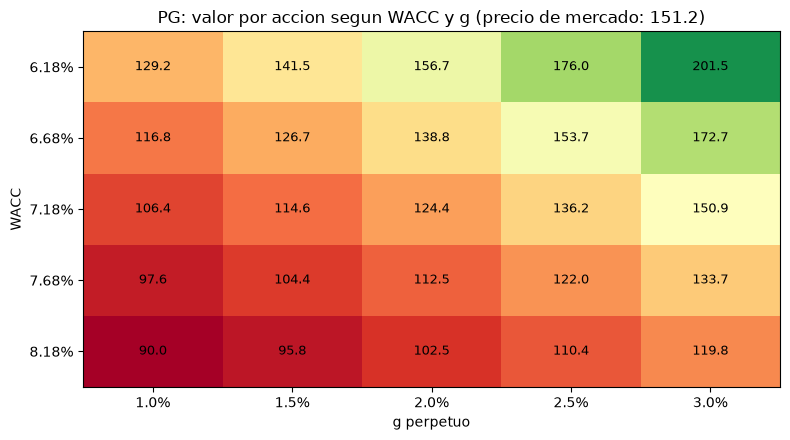

Celdas donde el modelo supera al precio: 5 de 25
Rango del modelo: 90.04 a 201.49 | precio: 151.23


In [19]:
dif = tabla.values.astype(float) / px_mercado - 1
lim = np.abs(dif).max()

fig, ax = plt.subplots(figsize=(8, 4.5))
im = ax.imshow(dif, cmap="RdYlGn", vmin=-lim, vmax=lim, aspect="auto")
ax.set_xticks(range(len(tabla.columns)), tabla.columns)
ax.set_yticks(range(len(tabla.index)), tabla.index)
ax.set_xlabel("g perpetuo"); ax.set_ylabel("WACC")
for i in range(tabla.shape[0]):
    for j in range(tabla.shape[1]):
        ax.text(j, i, f"{tabla.values[i, j]:.1f}", ha="center", va="center", fontsize=9)
ax.set_title(f"{TICKER}: valor por accion segun WACC y g (precio de mercado: {px_mercado:.1f})")
plt.tight_layout(); plt.show()

subvaluada = int((tabla.values.astype(float) > px_mercado).sum())
print(f"Celdas donde el modelo supera al precio: {subvaluada} de {tabla.size}")
print(f"Rango del modelo: {tabla.values.min():,.2f} a {tabla.values.max():,.2f} | precio: {px_mercado:,.2f}")

In [20]:
vp_flujos = sum(f / (1 + WACC) ** i for i, f in proy.items())
filas = {}
for m in [12.0, 13.3, 14.0, 15.0, 15.4, 16.0]:
    ev = vp_flujos + valor_terminal_multiplo(ebitda_5, m) / (1 + WACC) ** 5
    filas[f"{m:.1f}x"] = (ev - deuda_neta) / acciones
pd.Series(filas, name="valor por acción").round(2)

12.0x    117.32
13.3x    127.98
14.0x    133.72
15.0x    141.93
15.4x    145.21
16.0x    150.13
Name: valor por acción, dtype: float64

El precio (151.23) cae dentro del rango de 90 a 201. El modelo lo supera en 5 de 25 escenarios. Para justificarlo hace falta un WACC cercano a 6.7 % con g de 2.5 %, o un múltiplo de salida de unas 16x.